Fetching data directly from GitHub...


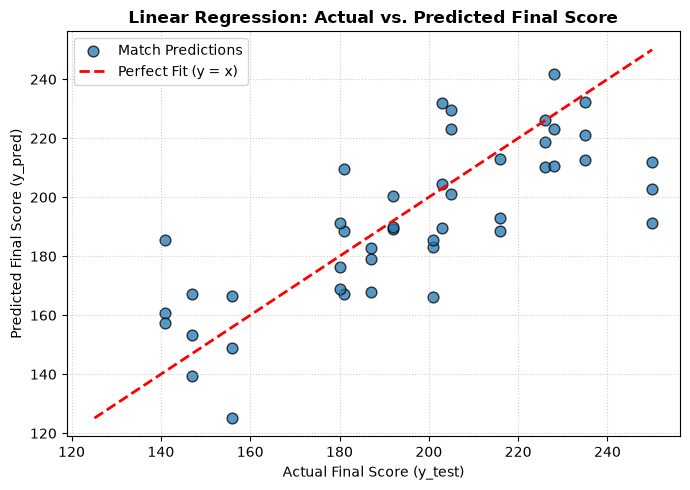

Success! Graph generated and saved to output/predicted_vs_actual.png


In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupShuffleSplit

# Ensure output directory exists locally
os.makedirs('../output', exist_ok=True)
os.makedirs('output', exist_ok=True)

# Read directly from GitHub Raw URL — no local file download needed!
url = 'https://raw.githubusercontent.com/jujharsingh1532/Cricket-score-predictor/main/data/ipl_score_prediction.csv'

df = pd.read_csv(url)

# Extract features and target
X = df[['Overs', 'Current_Runs', 'Wickets']]
y = df['Final_Runs']
groups = df['Match_ID']

# Train-Test Split matching model_training.ipynb
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# Train Model & Predict
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Plot Actual vs Predicted
plt.figure(figsize=(7, 5))
plt.scatter(
    y_test,
    y_pred,
    color='#1f77b4',
    alpha=0.75,
    edgecolors='k',
    s=60,
    label='Match Predictions',
)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color='red',
    linestyle='--',
    linewidth=2,
    label='Perfect Fit (y = x)',
)

plt.title(
    'Linear Regression: Actual vs. Predicted Final Score',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Actual Final Score (y_test)', fontsize=10)
plt.ylabel('Predicted Final Score (y_pred)', fontsize=10)
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()

# Save plot to output folder
plt.savefig('output/predicted_vs_actual.png', dpi=300)
plt.show()

